# Archive of ActivityLevelsCehcks..ipynb

Cells moved out of the working notebook because they make exhibits that are not in the final paper (AFG_paper_revised.docx), or are exploratory. They are kept as they were and are not maintained; they may depend on variables defined in the original notebook.

## Moved from `ActivityLevelsCehcks..ipynb`: cells 2ed33939, 044a5a89, 4f0b3c47, f7840dec, a18a6887, 46de3630, a032c017, 498e4655, 120bb0b3, 6bdae71b, 0c04534e, 57dddc16, 794f3b31, 69d75d43, 1ccfacb9, bb88634a, 862c63a2, 8eb69405, 377a5b92, a13f2050, a115885a, 9776319a, 4ca62730, 1818c524, fd43d07b, 2167dc56, b1f1fea4, eb832382

In [308]:
df_act.columns

Index(['weekdayThisAreaIsActive', 'instrument', 'image_id', 'date', 'mktID',
       'mktDay', 'weekday', 'activity_measure_area', 'activity_measure',
       'diff_to_median_time', 'clear_percent', 'marketlat', 'marketlon',
       'country', 'admLvl1', 'activity_area_norm2018',
       'activity_area_norm2019', 'activity_area_norm2020',
       'activity_area_norm2021', 'activity_area_norm2022',
       'activity_area_norm2023', 'un_region', '_merge', 'year'],
      dtype='object')

## Summary table: markets by category and market-day activity signal

All 137 markets by how the satellite-detected (MAI) days compare with the field validation. For the
43 tested markets, the table also gives the share of **days** in each signal class (2025):

- **Above non-market days:** the day's mean activity is higher than on the comparison days (p < 0.05,
  one-tailed Welch). For the 4 markets with no main day, the MAI Friday is compared with the other six
  days. For the 5 markets with no trading day reported (group F), the detected day is compared with the
  other weekdays. For the partial and no-match markets, each day is compared with the weekdays that neither
  source names.
- **Not above non-market days:** p >= 0.05. This includes days whose mean is lower.
- **Insufficient data:** no 2025 readings on that day, or a market where the activity variable runs
  opposite to raw activity (not tested). Days with few readings keep their test result.

The exact-match rows are not tested in this notebook, so their figures are entered by hand.

In [329]:
# --- Table: markets by category and market-day activity signal ----------------------
# Exact-match rows are entered by hand (not tested here); the rows for the 43 tested markets
# (groups A-F) come from the tests above. summary_table is
# reused for the second activity measure below.
N_TOTAL = 137
SIGNAL = {"yes": "Above non-market days", "no": "Not above non-market days",
          "no data": "Insufficient data"}
PCT_COLS = ["Share of markets", *SIGNAL.values()]
pct = lambda v: "" if pd.isna(v) else v if isinstance(v, str) else f"{v:.0%}"
num = lambda v: "" if pd.isna(v) else f"{int(v)}"


def tab_row(category, days="", n_markets=np.nan, flags=None, given=None):
    """One table row. `flags` are day-level 'yes' / 'no' / 'no data' results; `given` are
    hand-entered shares (above, not above, insufficient) or 'NA'."""
    row = {"Category": category, "Days named by": days, "Markets": n_markets,
           "Share of markets": n_markets / N_TOTAL, "Days tested": np.nan}
    if flags is not None:
        c = flags.value_counts().reindex(list(SIGNAL), fill_value=0)
        row["Days tested"] = int(c.sum())
        row.update({SIGNAL[k]: c[k] / c.sum() for k in SIGNAL})
    elif given is not None:
        row.update(dict(zip(SIGNAL.values(), [given] * 3 if given == "NA" else given)))
    return row


def summary_table(res, ov, ed, var):
    """The summary table for one activity variable, displayed and saved to Excel."""
    a_flags = res.loc[res.group == "A", "p_one_tailed"].map(distinctive)
    f_flags = res.loc[res.group == "F", "p_one_tailed"].map(distinctive)
    t = pd.DataFrame([
        tab_row("Exact match", "Complete day overlap", 86, given=(1.0, 0.0, 0.0)),
        tab_row("Exact match", "Continuously operating markets", 8, given=(0.5, 0.5, 0.0)),
        tab_row("Continuous operating market, no main day", "MAI (Fri vs other six days)", len(a_flags), a_flags),
        tab_row("Partial day overlap", n_markets=len(OV_MKTS)),
        tab_row("", "Both sources", flags=ov.loc[ov.role == "overlap", "distinctive"]),
        tab_row("", "MAI only", flags=ov.loc[ov.role == "ours-only", "distinctive"]),
        tab_row("", "Field only", flags=ov.loc[ov.role == "field-only", "distinctive"]),
        tab_row("Days do not match", n_markets=len(E_MKTS)),
        tab_row("", "MAI", flags=ed.loc[ed.role == "predicted", "distinctive"]),
        tab_row("", "Field", flags=ed.loc[ed.role == "field", "distinctive"]),
        tab_row("No trading day reported", "MAI (detected day vs other days)", len(f_flags), f_flags),
    ])
    assert t.Markets.sum() == N_TOTAL
    t = pd.concat([t, pd.DataFrame([tab_row("Total markets", "", N_TOTAL)])], ignore_index=True)
    print(f"Markets by category and market-day activity signal, {YEAR} ({var})")
    display(t.style.format({**{c: pct for c in PCT_COLS}, "Markets": num, "Days tested": num})
            .hide(axis="index"))

    path = os.path.join(OUT_VAL, f"market_day_validation_table_{YEAR}_{var}.xlsx")
    with pd.ExcelWriter(path, engine="openpyxl") as xw:
        t.to_excel(xw, sheet_name="table", index=False)
        ws = xw.sheets["table"]
        for col in ws.columns:
            ws.column_dimensions[col[0].column_letter].width = max(len(str(c.value or "")) for c in col) + 2
            if col[0].value in PCT_COLS:
                for c in col[1:]:
                    c.number_format = "0%"
    print("saved", path)
    return t


TABLE = summary_table(RES, OV, ED, ACTIVITY_VAR)

Markets by category and market-day activity signal, 2025 (activity_area_norm2022)


Category,Days named by,Markets,Share of markets,Days tested,Above non-market days,Not above non-market days,Insufficient data
Exact match,Complete day overlap,86,63%,,100%,0%,0%
Exact match,Continuously operating markets,8,6%,,50%,50%,0%
"Continuous operating market, no main day",MAI (Fri vs other six days),4,3%,4,50%,50%,0%
Partial day overlap,,21,15%,,,,
,Both sources,,,22,95%,5%,0%
,MAI only,,,8,88%,12%,0%
,Field only,,,19,26%,74%,0%
Days do not match,,13,9%,,,,
,MAI,,,17,76%,24%,0%
,Field,,,17,12%,88%,0%


saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\market_day_validation\market_day_validation_table_2025_activity_area_norm2022.xlsx


## Mirror: the same tests with `activity_measure` (asleep)

**Switched off:** the code cells in this section are commented out; the analysis focuses on `activity_area_norm2022`. Uncomment them to run the mirror again.

Every market-day validation test above, rerun with `activity_measure` (the raw activity measure, not
normalized; always positive) in place of the main variable (`ACTIVITY_VAR`). The markets, day sets, years,
thresholds and the one-reading-per-market-per-date panel are the same. `activity_measure` is missing on
about one row in five, so some weekdays have fewer readings (see the coverage report).

Results carry a `_2` suffix (`RES_2`, `OV_2`, `ED_2`, ...). Output files are named by measure, so the
main variable's files are not overwritten. The last cells compare the two measures.

In [332]:
# ASLEEP: activity_measure mirror switched off. Uncomment the lines below to run it.
# # --- Mirror: data, coverage and the 2025 tests with activity_measure ------------------
# VAR_2 = "activity_measure"
# GROUP_SHEETS_2 = {"A": {}, "Overlap B-D": {}, "No overlap E": {}}
# PANEL_2, has_read_2 = build_panel(VAR_2)
# notes_2 = coverage_report(VAR_2, PANEL_2, has_read_2)
# RES_2 = run_tests(VAR_2, PANEL_2, has_read_2, notes_2)
# write_excel(RES_2, VAR_2)

### Group A with `activity_measure`

Main test as above (detected Friday vs the other six days). The follow-up by year covers all four
markets, because the markets without a Friday peak in 2025 can differ between the measures.

In [333]:
# ASLEEP: activity_measure mirror switched off. Uncomment the lines below to run it.
# show_main("A", RES_2, PANEL_2, VAR_2, GROUP_SHEETS_2)
#
# FU_A_2 = {}
# for m, r in MKT[MKT.group == "A"].iterrows():
#     t = by_year(m, {FRI}, var=VAR_2)
#     t["same_every_day"] = np.where(t.p_test_gt_other.isna() | t.p_anova_equal_days.isna(), "n/a",
#                                    np.where((t.p_test_gt_other >= ALPHA) & (t.p_anova_equal_days >= ALPHA), "yes", "no"))
#     FU_A_2[r.district] = t
#     GROUP_SHEETS_2["A"][f"Follow-up: {r.district} by year"] = t
#     print(f"{r.district} ({m}): Friday vs the other six days, by year")
#     display(t[BY_YEAR_SHOW + ["same_every_day"]].round(3))

### Partially overlapping schedules with `activity_measure` (21 markets: groups B, C and D)

In [334]:
# ASLEEP: activity_measure mirror switched off. Uncomment the lines below to run it.
# OV_2 = day_tests(OV_MKTS, panel=PANEL_2)
# OV_COUNTS_2 = day_counts(OV_2, OV_ROLE_ORDER)
# print(f"{len(OV_MKTS)} markets with partially overlapping schedules; days with distinctive market-day "
#       f"activity in {YEAR} ({VAR_2}, vs the days neither source names):")
# display(OV_COUNTS_2)
# for role in OV_ROLE_ORDER:
#     print(f"\n{role} days with distinctive activity: {list_days(OV_2, role)}")
#     print(f"{role} days without data: {list_days(OV_2, role, 'no data')}")
# GROUP_SHEETS_2["Overlap B-D"]["Day-level tests, 2025 (each day vs the days neither source names)"] = OV_2
# GROUP_SHEETS_2["Overlap B-D"]["Counts by role, 2025"] = OV_COUNTS_2.reset_index()
# display(OV_2[["group", "district", "mktID", "role", "day", "n_day", "n_comparison", "mean_day",
#               "mean_comparison", "diff", "p_one_tailed", "distinctive", "low_power"]].round(3))
#
# # Disputed days compared directly: ours-only vs field-only (markets that have both)
# OV_DIRECT_2 = direct(OV_MKTS, "ours-only", "field-only", panel=PANEL_2)
# GROUP_SHEETS_2["Overlap B-D"]["Direct comparison, ours-only vs field-only days, 2025"] = OV_DIRECT_2
# print(f"{len(OV_DIRECT_2)} markets have both ours-only and field-only days:")
# display(OV_DIRECT_2.round(3))
# for g in ["B", "C", "D"]:
#     plot_markets(MKT.index[MKT.group == g].tolist(), f"Group {g}: {GROUP_TITLE[g]}",
#                  f"weekday_profile_{VAR_2}_group_{g}.png", panel=PANEL_2, var=VAR_2)

In [335]:
# ASLEEP: activity_measure mirror switched off. Uncomment the lines below to run it.
# # Timing (2018-2025) with activity_measure
# OV_FIELD_T_2, OV_FIELD_Y_2 = timing(OV_2[(OV_2.role == "field-only") & (OV_2.distinctive == "yes")], VAR_2)
# OV_OURS_T_2, OV_OURS_Y_2 = timing(OV_2[(OV_2.role == "ours-only") & (OV_2.distinctive == "yes")], VAR_2)
# OV_OURS_NO_T_2, OV_OURS_NO_Y_2 = timing(OV_2[(OV_2.role == "ours-only") & (OV_2.distinctive == "no")], VAR_2)
# for title, t, y, cols in [
#         ("Field-only days with distinctive activity in 2025: first year of market-day activity",
#          OV_FIELD_T_2, OV_FIELD_Y_2, ["first_year_market_like", "market_like_since"]),
#         ("Ours-only days with distinctive activity in 2025: last year without market-day activity",
#          OV_OURS_T_2, OV_OURS_Y_2, ["last_year_not_market_like", "market_like_since"]),
#         ("Ours-only days without distinctive activity in 2025: last year with market-day activity",
#          OV_OURS_NO_T_2, OV_OURS_NO_Y_2, ["last_year_market_like"])]:
#     print(f"\n{title} ({len(t)} days)")
#     if len(t):
#         display(t[["group", "district", "mktID", "day", "years_market_like"] + cols])
#         GROUP_SHEETS_2["Overlap B-D"][title] = t
#         GROUP_SHEETS_2["Overlap B-D"][title.split(":")[0] + ", by year"] = y

### No overlapping operating day with `activity_measure` (13 markets: group E)

In [336]:
# ASLEEP: activity_measure mirror switched off. Uncomment the lines below to run it.
# ED_2 = day_tests(E_MKTS, E_LABELS, panel=PANEL_2)
# E_COUNTS_2 = day_counts(ED_2, E_ROLE_ORDER)
# print(f"{len(E_MKTS)} markets with no overlapping day; days with activity above the non-market days in "
#       f"{YEAR} ({VAR_2}):")
# display(E_COUNTS_2)
# for role in E_ROLE_ORDER:
#     print(f"\n{role} days above the non-market days: {list_days(ED_2, role)}")
#     print(f"{role} days without data: {list_days(ED_2, role, 'no data')}")
# GROUP_SHEETS_2["No overlap E"]["Day-level tests, 2025 (each day vs the days neither source names)"] = ED_2
# GROUP_SHEETS_2["No overlap E"]["Counts by role, 2025"] = E_COUNTS_2.reset_index()
# display(ED_2[["district", "mktID", "role", "day", "n_day", "n_comparison", "mean_day", "mean_comparison",
#               "diff", "p_one_tailed", "distinctive", "low_power"]].round(3))
#
# # Predicted days vs field days, compared directly (pooled within each source)
# E_DIRECT_2 = direct(E_MKTS, "ours-only", "field-only", E_LABELS, panel=PANEL_2)
# GROUP_SHEETS_2["No overlap E"]["Direct comparison, predicted vs field days, 2025"] = E_DIRECT_2
# display(E_DIRECT_2.round(3))
# plot_markets(E_MKTS, f"Group E: {GROUP_TITLE['E']}", f"weekday_profile_{VAR_2}_group_E.png",
#              panel=PANEL_2, var=VAR_2)

In [337]:
# ASLEEP: activity_measure mirror switched off. Uncomment the lines below to run it.
# # Timing (2018-2025) with activity_measure
# E_PRED_T_2, E_PRED_Y_2 = timing(ED_2[(ED_2.role == "predicted") & (ED_2.distinctive == "yes")], VAR_2)
# E_FIELD_T_2, E_FIELD_Y_2 = timing(ED_2[(ED_2.role == "field") & (ED_2.distinctive == "yes")], VAR_2)
# E_PRED_NO_T_2, E_PRED_NO_Y_2 = timing(ED_2[(ED_2.role == "predicted") & (ED_2.distinctive == "no")], VAR_2)
# for title, t, y, cols in [
#         ("Predicted days above the non-market days in 2025: last year they stopped",
#          E_PRED_T_2, E_PRED_Y_2, ["last_year_not_market_like", "market_like_since"]),
#         ("Field days above the non-market days in 2025: first year they started",
#          E_FIELD_T_2, E_FIELD_Y_2, ["first_year_market_like", "market_like_since"]),
#         ("Predicted days not above the non-market days in 2025: last year they were",
#          E_PRED_NO_T_2, E_PRED_NO_Y_2, ["last_year_market_like"])]:
#     print(f"\n{title} ({len(t)} days)")
#     if len(t):
#         display(t[["district", "mktID", "day", "years_market_like"] + cols])
#         GROUP_SHEETS_2["No overlap E"][title] = t
#         GROUP_SHEETS_2["No overlap E"][title.split(":")[0] + ", by year"] = y

### Timing of weekday activity signals, summary table and overall results with `activity_measure`

In [338]:
# ASLEEP: activity_measure mirror switched off. Uncomment the lines below to run it.
# # --- Mirror: timing figure, summary table and workbook --------------------------------
# OV_BOTH_NO_T_2, OV_BOTH_NO_Y_2 = timing(OV_2[(OV_2.role == "overlap") & (OV_2.distinctive == "no")], VAR_2)
# GROUP_SHEETS_2["Overlap B-D"]["Overlap days without distinctive activity in 2025: last year with market-day activity"] = OV_BOTH_NO_T_2
# GROUP_SHEETS_2["Overlap B-D"]["Overlap days without distinctive activity in 2025, by year"] = OV_BOTH_NO_Y_2
# TIMING_2 = timing_table(RES_2, FU_A_2, [OV_BOTH_NO_T_2, OV_OURS_NO_T_2, E_PRED_NO_T_2], [OV_FIELD_T_2, E_FIELD_T_2])
# GROUP_SHEETS_2["Timing"] = {"Timing of weekday activity signals (figure data)": TIMING_2}
# plot_timing(TIMING_2, VAR_2, f"timing_weekday_activity_signals_{VAR_2}.png")
#
# TABLE_2 = summary_table(RES_2, OV_2, ED_2, VAR_2)
#
# A_RES_2 = RES_2[RES_2.group == "A"][["district", "mktID", "p_one_tailed", "assigned_to"]]
# print(f"Group A ({YEAR}, {VAR_2}): detected Friday vs the other six days")
# display(A_RES_2.round(3))
# print("Partially overlapping schedules (21 markets): days with distinctive market-day activity")
# display(OV_COUNTS_2)
# print("No overlapping day (14 markets): days with activity above the non-market days")
# display(E_COUNTS_2)
# write_by_group(VAR_2,
#                {f"Group A, {YEAR}": A_RES_2,
#                 "Partially overlapping schedules: days with distinctive activity": OV_COUNTS_2.reset_index(),
#                 "No overlapping day: days with activity above the non-market days": E_COUNTS_2.reset_index()},
#                GROUP_SHEETS_2)

### Comparison: main variable vs `activity_measure`

In [339]:
# ASLEEP: activity_measure mirror switched off. Uncomment the lines below to run it.
# # --- Comparison of the two measures -------------------------------------------------
# V1, V2 = ACTIVITY_VAR, VAR_2
# KEY = ["group", "district", "mktID", "role", "day"]
#
# A_CMP = A_RES.merge(A_RES_2, on=["district", "mktID"], suffixes=(f"_{V1}", f"_{V2}"))
# print("Group A: Friday peak (MAI) or none (Field), by measure")
# display(A_CMP.round(3))
#
# DAY_CMP = pd.concat([d1[KEY + ["distinctive", "p_one_tailed"]].merge(
#                          d2[KEY + ["distinctive", "p_one_tailed"]], on=KEY, suffixes=(f"_{V1}", f"_{V2}"))
#                      for d1, d2 in [(OV, OV_2), (ED, ED_2)]], ignore_index=True)
# print(f"\nDay-level signal in {YEAR}: {V1} (rows) vs {V2} (columns), by role")
# display(pd.crosstab([DAY_CMP.role, DAY_CMP[f"distinctive_{V1}"]], DAY_CMP[f"distinctive_{V2}"]))
# DAY_DIFF = DAY_CMP[DAY_CMP[f"distinctive_{V1}"] != DAY_CMP[f"distinctive_{V2}"]]
# print(f"\n{len(DAY_DIFF)} of {len(DAY_CMP)} days change class between the measures:")
# display(DAY_DIFF.round(3))
#
# print("\nSummary table, by measure")
# display(pd.DataFrame({"Category": TABLE.Category, "Days named by": TABLE["Days named by"],
#                       **{f"{s} ({v})": t[s].map(pct) for s in SIGNAL.values() for v, t in [(V1, TABLE), (V2, TABLE_2)]}}))
#
# TIMING_CMP = TIMING[["panel", "district", "mktID", "day", "year"]].merge(
#     TIMING_2[["panel", "district", "mktID", "day", "year"]], on=["panel", "district", "mktID", "day"],
#     how="outer", suffixes=(f"_{V1}", f"_{V2}")).sort_values(["panel", "district", "day"])
# print("\nTiming figure data, by measure (blank: the day is not in that measure's panel)")
# display(TIMING_CMP)

**Summary: `activity_area_norm2020` vs `activity_measure`** (from the last run, when `activity_area_norm2020` was the main variable)

- **Coverage:** `activity_measure` has no 2025 reading on some weekdays in some markets:
  - Nawzad Thu and Bakwa Sat have none at all. These are the two field-reported days that the area measure
    finds as market days that started in 2023, so the schedule change in those markets cannot be checked with
    this measure.
  - The comparison days of Nahr-e-Saraj lon64_4065 have a single reading, so none of its three days can be
    tested.
  - In Andar, under 40% of non-Friday images have a reading.
- **Group A:** Maydanshahr still shows no Friday peak (p = 0.36), and Birmil and Urgun still show one. Andar
  now shows a Friday peak in 2025 (p < 0.001), but on low coverage of the other six days (55 dates against
  151 with the area measure).
- **Day level:** 15 of the 85 days change class.
  - **8 gain a signal:** seven predicted days (Nad-e-Ali lon64_0787 Tue, Almar lon64_5285 Fri, Murghab Mon,
    Kajaki Sun and Wed, Nawzad Sat, Bakwa Fri) and one field-only day (Nahr-e-Saraj lon64_7449 Mon).
  - **2 lose it:** the field-only days Alishang Tue and Muhmanddara Fri.
  - **5 have no data:** the three Nahr-e-Saraj lon64_4065 days, Nawzad Thu and Bakwa Sat.
- **Summary table:** with `activity_measure`, every predicted day in the no-match markets is above the
  non-market days (18 of 18, against 14 with the area measure), and no field day is (0 of 18, 2 with no
  data). MAI-only days in the partial-overlap markets rise from 75% to 88%.
- **Timing:**
  - **Panel A:** only Maydanshahr Fri remains, with its last signal in 2023 (2019 with the area measure).
  - **Panel B:** four field-only days. Qades Sat is dated 2019, Washer lon64_3886 Fri 2020, Washer
    lon64_2906 Sat 2021 and Nahr-e-Saraj lon64_7449 Mon 2025. The two Washer days have few 2025 readings
    (4 and 7 dates).

## Markets by goods sold

All 137 markets by the goods the WFP field validation reports (`market_validation_corrected.xlsx`, sheet
"Market list", column `category_label`). Car markets are the markets selling general goods only. Two
Baghlan markets are not in the WFP list.

In [340]:
# --- Table: markets by goods sold -----------------------------------------------------
GOODS_XLSX = os.path.join(DATA, "WFP_validation", "market_validation_corrected.xlsx")
GOODS_ROWS = [   # (block, row, category_label values)
    ("Food is sold", "Food only", ["Food only"]),
    ("Food is sold", "Food and livestock", ["Food and livestock, no general goods"]),
    ("Food is sold", "Food and general goods", ["Food and general goods, no livestock", "All goods, unspecified"]),
    ("Food is sold", "Food, livestock and general goods", ["Food, livestock and general goods"]),
    ("Food not sold", "Livestock only", ["Livestock only"]),
    ("Food not sold", "General goods only (car markets)", ["General goods only"]),
    ("Not specified", "", ["Not specified"]),
]

goods = pd.read_excel(GOODS_XLSX, sheet_name="Market list")[["mktID", "category_label", "car_market"]]
goods = pd.DataFrame({"mktID": sorted(df_act.mktID.unique())}).merge(goods, on="mktID", how="left")
label_row = {lab: (blk, row) for blk, row, labs in GOODS_ROWS for lab in labs}
unmapped = set(goods.category_label.dropna()) - set(label_row)
assert not unmapped, f"goods labels without a table row: {unmapped}"
car = goods.car_market.astype(str).str.strip().str.lower().eq("yes")
print(f"car markets: {car.sum()}; general-goods-only markets: {(goods.category_label == 'General goods only').sum()}; "
      f"car markets with another label: {(car & (goods.category_label != 'General goods only')).sum()}")

goods["block"] = goods.category_label.map(lambda l: label_row[l][0] if l in label_row else "Not in WFP list")
goods["row"] = goods.category_label.map(lambda l: label_row[l][1] if l in label_row else "")
order = [(blk, row) for blk, row, _ in GOODS_ROWS] + [("Not in WFP list", "")]
GOODS_TABLE = (goods.groupby(["block", "row"]).size().reindex(pd.MultiIndex.from_tuples(order), fill_value=0)
               .rename("No. markets").reset_index().rename(columns={"level_0": "Goods", "level_1": ""}))
GOODS_TABLE["Share (%)"] = GOODS_TABLE["No. markets"] / GOODS_TABLE["No. markets"].sum()
GOODS_TABLE = pd.concat([GOODS_TABLE, pd.DataFrame([{"Goods": "Total markets", "": "",
                                                     "No. markets": GOODS_TABLE["No. markets"].sum(),
                                                     "Share (%)": 1.0}])], ignore_index=True)
assert GOODS_TABLE["No. markets"].iloc[-1] == N_TOTAL
GOODS_TABLE.loc[GOODS_TABLE.Goods.duplicated(), "Goods"] = ""         # show each block name once
display(GOODS_TABLE.style.format({"Share (%)": "{:.0%}"}).hide(axis="index"))

f = os.path.join(OUT_VAL, "markets_by_goods.xlsx")
with pd.ExcelWriter(f, engine="openpyxl") as xw:
    GOODS_TABLE.to_excel(xw, sheet_name="goods", index=False)
    goods.to_excel(xw, sheet_name="markets", index=False)
    for ws in xw.sheets.values():
        for col in ws.columns:
            ws.column_dimensions[col[0].column_letter].width = max(len(str(c.value or "")) for c in col) + 2
    for c in xw.sheets["goods"]["D"][1:]:
        c.number_format = "0%"
print("saved", f)

car markets: 3; general-goods-only markets: 3; car markets with another label: 0


Goods,,No. markets,Share (%)
Food is sold,Food only,29,21%
,Food and livestock,9,7%
,Food and general goods,28,20%
,"Food, livestock and general goods",48,35%
Food not sold,Livestock only,8,6%
,General goods only (car markets),3,2%
Not specified,,10,7%
Not in WFP list,,2,1%
Total markets,,137,100%


saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\market_day_validation\markets_by_goods.xlsx


**Secondary regressions.** Specification E with two changes:

- **E2:** keeps every market-year, even those without all four quarters, with the same year and access
  controls. Standard errors are heteroskedasticity-robust (HC1) instead of clustered on market.
- **E3:** as E2, with no year or access controls (`act ~ 0 + quarter x goods category`).

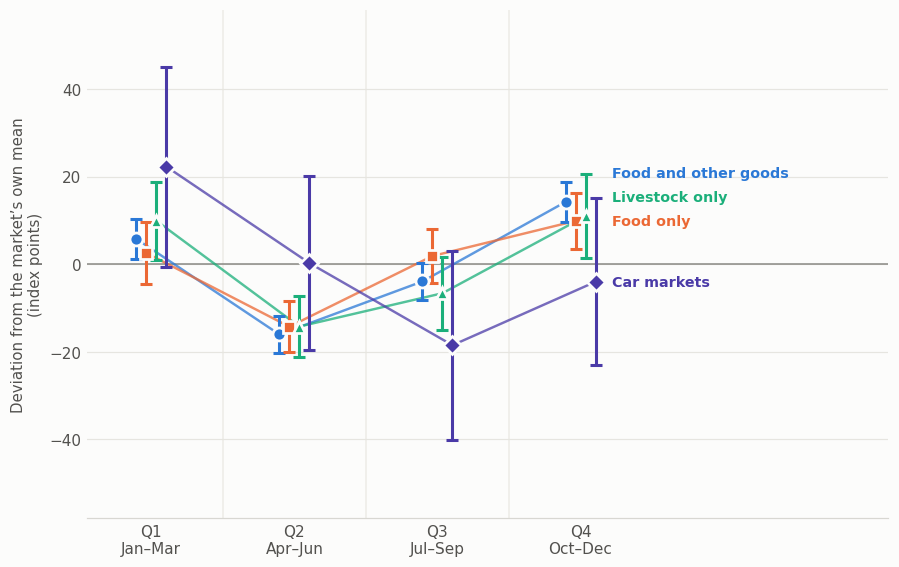

saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\seasonality\panel_E2.png


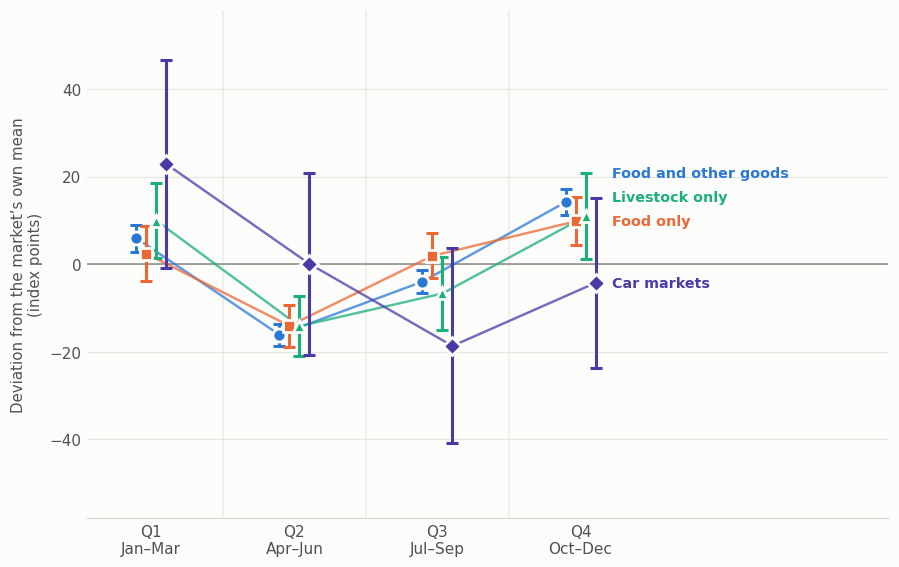

saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\seasonality\panel_E3.png
Sample by specification:


,markets,market-quarters
E,125,3628
E2,125,3848
E3,125,3848


Q4 - Q2 swing by goods group and specification (effect, SE, p):


E                    E2                     E3  \
                       swing     se      p   swing      se      p   swing   
Food and other goods  32.479  2.477  0.000  30.238   2.342  0.000  30.260   
Food only             25.952  3.420  0.000  24.137   4.247  0.000  23.847   
Livestock only        26.713  5.395  0.000  25.200   6.644  0.000  25.050   
Car markets            2.954  7.784  0.704  -4.261  16.380  0.795  -4.339   

                                     
                          se      p  
Food and other goods   2.369  0.000  
Food only              4.463  0.000  
Livestock only         7.275  0.001  
Car markets           17.248  0.801

In [343]:
# --- Specification E, secondary regressions: all market-years, robust standard errors ---
PE_Q_ALL = pe_build(full_years=False)
PE_SPECS = {   # name: (data, year and access controls, covariance, title, model note, SE note)
    "E": (PE_Q, True, "cluster", None, None, None),
    "E2": (PE_Q_ALL, True, "HC1", "E2.  All market-years, controlling for year and market access",
           "act ~ 0 + quarter × goods category + year + access, no constant. All market-years.\n"
           "Year and access enter additively, not interacted with quarter.", "robust (HC1)"),
    "E3": (PE_Q_ALL, False, "HC1", "E3.  All market-years, no controls",
           "act ~ 0 + quarter × goods category, no constant. All market-years.\n"
           "No year or access controls.", "robust (HC1)"),
}
PE_RES = {}
for name, (q, controls, cov, title, model, se_note) in PE_SPECS.items():
    m, B, SE, SW = pe_estimate(q, controls=controls, cov=cov)
    PE_RES[name] = dict(B=B, SE=SE, SW=SW, n_markets=q.Location.nunique(), n_obs=len(q))
    if name != "E":                                # E is drawn above
        pe_draw(B, SE, SW, q.Location.nunique(), len(q), os.path.join(OUT_SEAS, f"panel_{name}.png"),
                title=title, model=model, se_note=se_note)

print("Sample by specification:")
display(pd.DataFrame({n: {"markets": r["n_markets"], "market-quarters": r["n_obs"]} for n, r in PE_RES.items()}).T)
PE_SWINGS = pd.concat({n: pd.DataFrame(r["SW"], index=["swing", "se", "p"]).T for n, r in PE_RES.items()}, axis=1)
print("Q4 - Q2 swing by goods group and specification (effect, SE, p):")
display(PE_SWINGS.round(3))
PE_SWINGS.to_csv(os.path.join(OUT_SEAS, "panel_E_swings_by_specification.csv"))

**Specification E on a market-level quarterly index.** Same sample and clustered standard errors as
specification E. The outcome is each market-quarter's activity relative to that market-year's average:
100 x quarter mean / mean of the market-year's four quarterly means. Every market-year averages 100, so
differences in level between markets and between years drop out, and only the seasonal shape is left.
For the same reason the year and access dummies are exactly zero, so they are left out of this regression.

125 markets, 3,628 market-quarters, 2018-2025
Index distribution: {'count': 3628.0, 'mean': 100.0, 'std': 23.4, 'min': -5.7, '1%': 39.0, '50%': 100.2, '99%': 165.9, 'max': 217.4}

Cell levels (index):


,Q1,Q2,Q3,Q4
Food and other goods,105.16,85.23,96.58,113.02
Food only,101.76,88.53,100.48,109.23
Livestock only,110.39,88.20,92.53,108.88
Car markets,114.68,96.78,85.39,103.15


Q4 - Q2 swing (index points, SE, p):


,effect,se,p
Food and other goods,27.791,2.024,0.000
Food only,20.697,2.624,0.000
Livestock only,20.673,5.216,0.000
Car markets,6.365,7.574,0.401


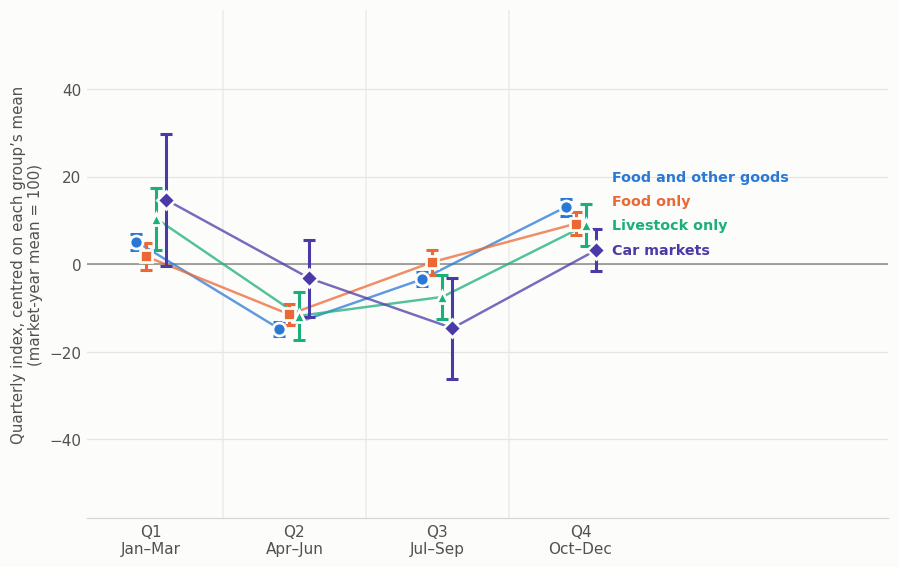

saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\seasonality\panel_E_index.png


In [344]:
# --- Specification E on a market-level quarterly index (market-year mean = 100) -----------
PE_Q_IDX = pe_build(index=True)
# Every market-year averages 100, so year and access dummies are exactly zero here (and their clustered
# variances numerically singular): they are left out, which leaves the other coefficients unchanged.
PE_M_IDX, PE_B_IDX, PE_SE_IDX, PE_SW_IDX = pe_estimate(PE_Q_IDX, controls=False)
print(f"{PE_Q_IDX.Location.nunique()} markets, {len(PE_Q_IDX):,} market-quarters, 2018-2025")
print("Index distribution:", PE_Q_IDX.act.describe(percentiles=[.01, .5, .99]).round(1).to_dict())
print("\nCell levels (index):")
display(PE_B_IDX.round(2))
print("Q4 - Q2 swing (index points, SE, p):")
display(pd.DataFrame(PE_SW_IDX, index=["effect", "se", "p"]).T.round(3))
pe_draw(PE_B_IDX, PE_SE_IDX, PE_SW_IDX, PE_Q_IDX.Location.nunique(), len(PE_Q_IDX),
        os.path.join(OUT_SEAS, "panel_E_index.png"),
        title="E.  Market-level quarterly index",
        model="index ~ 0 + quarter × goods category, no constant; index = 100 × quarter / market-year mean.\n"
              "Year and access controls drop out: every market-year averages 100.",
        ylabel="Quarterly index, centred on each group’s mean\n(market-year mean = 100)")

**Market-level quarterly index by market access.** The same regression as the index figure above, with
the three access categories (high, intermediate, remote) as the groups of interest instead of goods:
`index ~ 0 + quarter x access category`, standard errors clustered by market, 90% confidence intervals.
Every market has an access category, so markets without goods information also enter. The last table tests
whether the Q4 - Q2 swing differs between access categories.

In [ ]:
# --- Market-level quarterly index by market access (market-year mean = 100) ---------------
PE_Q_ACC = pe_build(index=True, by="access")
PE_M_ACC, PE_B_ACC, PE_SE_ACC, PE_SW_ACC = pe_estimate(PE_Q_ACC, controls=False, order=PA_ORDER, sh=PA_SH)
print(f"{PE_Q_ACC.Location.nunique()} markets, {len(PE_Q_ACC):,} market-quarters, 2018-2025")
print("Markets by access category:", PE_Q_ACC.groupby("group").Location.nunique().reindex(PA_ORDER).to_dict())
print("\nCell levels (index):")
display(PE_B_ACC.round(2))
print("Q4 - Q2 swing (index points, SE, p):")
display(pd.DataFrame(PE_SW_ACC, index=["effect", "se", "p"]).T.round(3))

# Does the Q4 - Q2 swing differ between access categories?
_k = lambda g, j: f"C(cell)[{PA_SH[g]}_Q{j}]"
_rows = []
for g1, g2 in [("High access", "Intermediate access"), ("High access", "Remote"), ("Intermediate access", "Remote")]:
    t = PE_M_ACC.t_test(f"({_k(g1, 4)} - {_k(g1, 2)}) - ({_k(g2, 4)} - {_k(g2, 2)}) = 0")
    _rows.append({"comparison": f"{g1} - {g2}", "difference": float(t.effect[0]), "se": float(t.sd[0, 0]),
                  "p": float(t.pvalue)})
print("Difference in the Q4 - Q2 swing between access categories:")
display(pd.DataFrame(_rows).round(3))

pe_draw(PE_B_ACC, PE_SE_ACC, PE_SW_ACC, PE_Q_ACC.Location.nunique(), len(PE_Q_ACC),
        os.path.join(OUT_SEAS, "panel_E_index_access.png"),
        title="E.  Market-level quarterly index, by market access",
        model="index ~ 0 + quarter × access category, no constant; index = 100 × quarter / market-year mean.\n"
              "Year and access controls drop out: every market-year averages 100.",
        ylabel="Quarterly index, centred on each group’s mean\n(market-year mean = 100)",
        style=PA_STYLE)